# CNN Lab: Binary Image Classification with PyTorch

**Topic:** Introduction to Convolutional Neural Networks  
**Task:** Build a CNN for binary classification (Cats vs Dogs)

In this lab, you will:
- load images from structured folders
- train a CNN on the training set
- monitor validation performance
- evaluate the model on the test set
- analyze errors

# Learning Objectives

By the end of this lab, you should be able to:

- explain why CNNs are well suited for images
- preprocess image data with PyTorch/torchvision
- build and train a CNN for binary classification
- interpret training and validation curves
- evaluate a model on a test set
- inspect prediction errors

# Before You Start

Answer these questions before running the notebook:

1. Why is a CNN more suitable than an MLP for image classification?

An MLP connects every pixel to every neuron of the first hidden layer, and it flattens the image, so it loses the 2D structure (which pixels are neighbours). For a 150x150x3 image (67,500 inputs) and 128 hidden units, the first dense layer alone has about 8.6 million weights. A CNN instead relies on:
- **local connectivity**: each neuron only looks at a small patch of the image (e.g. 3x3),
- **weight sharing**: the same filter is slid over the whole image, so a `Conv2d(3, 32, 3)` layer has only 896 parameters (about 10,000 times fewer than the dense layer above),
- **translation equivariance**: a feature (an edge, an ear, an eye...) is detected wherever it appears in the image.

These built-in assumptions match the nature of images (nearby pixels are correlated), so the CNN learns better features with far fewer parameters and less risk of overfitting.

2. What is the difference between a convolution layer and a pooling layer?

A **convolution layer** has **learnable weights** (its filters): it computes weighted sums over local patches of its input to detect features (edges, textures, then more complex shapes in deeper layers), producing feature maps.

A **pooling layer** has **no learnable parameters**: it applies a fixed operation (max or average) on small windows of the feature maps to downsample them. It reduces the spatial size (and therefore computation and the number of parameters in the following layers) and makes the representation more robust to small shifts of the input.

3. Why do we normalize image pixel values?

Raw pixel values lie in [0, 255]. Bringing them to a small range (here [0, 1] with `ToTensor()`) helps optimization:
- with large input values, activations and gradients can become very large during backpropagation (unstable training, exploding gradients), or saturate activations such as the sigmoid, whose gradient is then close to zero;
- with badly scaled inputs, the loss function is poorly conditioned (very steep in some directions, flat in others), so gradient descent zigzags and converges slowly;
- it lets us use standard weight initializations and learning rates, which are designed for inputs of order 1.

Note: dividing by 255 does not remove brightness differences between images, nor does it balance the color channels (they are already in the same range). For that, we would use a per-channel standardization such as `transforms.Normalize(mean, std)`.

4. Why is the output layer composed of a single neuron with a sigmoid activation in binary classification? *(Note: in PyTorch we will keep this neuron as a raw logit and apply the sigmoid implicitly inside the loss function — see Step 5.)*

In binary classification, the label y is 0 or 1, so it follows a Bernoulli distribution with parameter p = P(y = 1 | image), here P(dog). The network only needs to output this single number p: the probability of the other class is simply P(cat) = 1 − p, so one neuron is enough.

The sigmoid maps any real value to (0, 1), so its output can be interpreted as p. It is smooth and differentiable, and combined with the binary cross-entropy (the negative log-likelihood of the Bernoulli distribution) it gives a simple gradient (p − y).

In PyTorch, `BCEWithLogitsLoss` combines the sigmoid and the binary cross-entropy in a single, numerically more stable operation (it avoids computing log(0) when the sigmoid saturates), which is why the model outputs a raw logit.

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

print("PyTorch version:", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

KeyboardInterrupt: 

In [ ]:
print("Using device:", device)

Using device: cpu


# Step 1 — Import Libraries

We use:

- **NumPy** for numerical arrays
- **Matplotlib** for visualization
- **PyTorch / torchvision** to build and train the CNN
- **`ImageFolder` + `DataLoader`** to load and preprocess images (the torchvision equivalent of Keras's `ImageDataGenerator.flow_from_directory`)

In [ ]:
np.random.seed(42)
torch.manual_seed(42)

# Reproducibility

We set random seeds to make the experiment more reproducible.

**Question:**  
Why might the results still vary slightly from one run to another?

Training is stochastic: random weight initialization, random shuffling of the mini-batches, random dropout masks. Fixing the seed makes these random draws identical from one run to another, but some variability remains:
- **Non-deterministic GPU computations**: on CUDA, cuDNN may pick the fastest algorithm for convolutions, and some of these algorithms (and parallel operations such as atomic additions in the backward pass) are non-deterministic. Since floating-point addition is not associative, summing in a different order gives slightly different results, and these tiny differences accumulate over the training iterations. Full determinism would require `torch.backends.cudnn.deterministic = True`, `torch.backends.cudnn.benchmark = False` (or `torch.use_deterministic_algorithms(True)`), at the cost of speed.
- **Order of execution in the notebook**: the seed is set only once. Any cell that consumes random numbers (e.g. iterating over the shuffled `train_generator` to visualize a batch) changes the state of the random generator, so re-running cells or running them in a different order changes the initialization and the batch order.
- **Seeds not covering every source of randomness**: Python's `random` module is not seeded here, and if the DataLoader uses `num_workers > 0`, any NumPy/`random` calls inside the worker processes need a `worker_init_fn` to be seeded properly.
- **Different environment**: another GPU/CPU, another driver, or other library versions (PyTorch, CUDA, cuDNN) can produce slightly different numerical results.

# Step 2 — Prepare the Dataset

We propose to use an existing dataset of dogs and cats available on this link:
https://drive.google.com/file/d/1FVomvGZ9dQhuc_DG4qc6yumM-NXJOzVx/view?usp=sharing

The complete dataset is also available on the Kaggle platform:
https://www.kaggle.com/c/dogs-vs-cats-redux-kernels-edition/data

Download the image database from the google drive link and extract it and you can then get the data:

- `data/train/cats`
- `data/train/dogs`
- `data/validation/cats`
- `data/validation/dogs`
- `data/test/cats`
- `data/test/dogs`

In [ ]:
# Running locally: no Google Drive needed.
# The data (train/ valid/ test/) is already next to this notebook.

In [ ]:
# Running locally: nothing to unzip, the images are already extracted.

In [ ]:
base_dir = "."  # train/, valid/, test/ live next to this notebook

train_dir = os.path.join(base_dir, "train")
validation_dir = os.path.join(base_dir, "valid")
test_dir = os.path.join(base_dir, "test")

print("Train directory exists:", os.path.exists(train_dir))
print("Validation directory exists:", os.path.exists(validation_dir))
print("Test directory exists:", os.path.exists(test_dir))

Train directory exists: True
Validation directory exists: True
Test directory exists: True


# Quick Check

**Questions:**

1. Why do we separate training and validation data?

The model is fitted on the training set, so its performance on these images is optimistic: it has already seen them. The validation set contains images the model never learns from, so it gives an estimate of how well the model **generalizes** to new data. It is used during development to:
- **detect overfitting**: if, after a given number of epochs, the validation loss starts growing again while the training loss keeps decreasing, the model starts memorizing the training images instead of learning general features (this tells us when to stop training, e.g. with early stopping);
- **choose hyperparameters and compare models** (learning rate, number of filters, dropout rate, number of epochs, data augmentation...).

Since these choices are made by looking at the validation set, it indirectly influences the model; this is why a separate **test set** is kept aside for the final, unbiased evaluation.

2. What could happen if we evaluated the model only on training images?

We would get an over-optimistic estimate of the performance. A model with enough parameters (here about 4.8 million) can memorize the training images, reaching a very high training accuracy while performing poorly on new images. Evaluating only on training data, we could not detect this overfitting, and we would pick the model that memorizes best rather than the one that generalizes best.

(This is not data leakage in the strict sense: data leakage is when information from the validation/test data leaks into training, e.g. the same image appearing in both sets. But the consequence is similar: the measured performance does not reflect performance on unseen data.)

In [ ]:
# Create Datasets and DataLoaders

# We rescale pixel values to the range [0,1] via ToTensor(), and resize every image to 150x150.
# This is the torchvision equivalent of ImageDataGenerator(rescale=1./255).

image_size = (150, 150)
batch_size = 32

basic_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),  # scales pixel values to [0, 1]
])

In [ ]:
train_dataset = datasets.ImageFolder(train_dir, transform=basic_transform)
validation_dataset = datasets.ImageFolder(validation_dir, transform=basic_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=basic_transform)

train_generator = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
validation_generator = DataLoader(validation_dataset, batch_size=batch_size, shuffle=False)
test_generator = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("Class to index mapping:", train_dataset.class_to_idx)

Class to index mapping: {'cats': 0, 'dogs': 1}


# Step 3 — Load the Images

We use `datasets.ImageFolder` + `DataLoader` to:

- read the images directly from folders
- resize them to `150 x 150`
- normalize them using `ToTensor()` (scales to `[0, 1]`)
- assign labels automatically from folder names

**Questions:**

1. Why is normalization useful here?

As explained in "Before You Start", `ToTensor()` brings the pixel values from [0, 255] to [0, 1]. Inputs of order 1 keep activations and gradients in a reasonable range during backpropagation (no exploding gradients, no saturation of the sigmoid), make the loss better conditioned so gradient descent converges faster and more stably, and are consistent with the default weight initialization and the learning rate `1e-4`.

2. Why do we resize all images to the same size?

The original images have different sizes, but the network needs a fixed input size:
- the convolution and pooling layers could process any size, but the size of their output depends on the input size. The first dense layer `nn.Linear(128 * 17 * 17, 128)` expects exactly 36,992 inputs, which is only true for 150x150 images; any other size would produce a different number of features and the matrix multiplication would fail;
- the `DataLoader` stacks the images of a batch into a single tensor of shape `(32, 3, 150, 150)`, which is only possible if they all have the same shape.

150x150 is also a compromise: large enough to keep the details needed to distinguish cats from dogs, small enough to keep training fast.

3. What labels do you expect for the two classes?

cats: 0, dogs: 1. `ImageFolder` assigns the labels from the sub-folder names sorted alphabetically ("cats" comes before "dogs"), as confirmed by the output `Class to index mapping: {'cats': 0, 'dogs': 1}`. So the sigmoid output of the model is interpreted as the probability that the image is a dog.

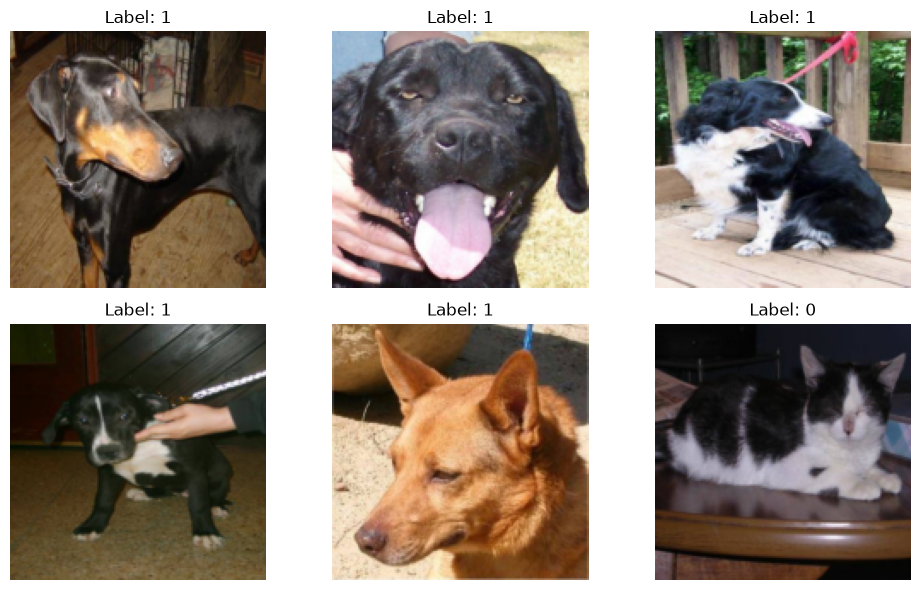

In [ ]:
# Visualize a Batch of Training Images

images, labels = next(iter(train_generator))

plt.figure(figsize=(10, 6))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    # images are (C, H, W) tensors in [0, 1]; permute to (H, W, C) for imshow
    plt.imshow(images[i].permute(1, 2, 0).numpy())
    plt.title(f"Label: {int(labels[i])}")
    plt.axis("off")
plt.tight_layout()
plt.show()


# Visual Inspection

**Questions:**

1. Are the images easy for a human to classify?

Yes: in every image of the batch, a human immediately recognizes a cat or a dog. However, the images are far from uniform, which makes the task harder for a model than it looks:
- **varied conditions**: indoor photos with flash, dark backgrounds, outdoor photos on grass;
- **cluttered backgrounds and other objects**: blankets, a red armchair, a cage, a person holding the cat, a date stamp printed on the photo;
- **varied poses, scales and number of animals**: an animal seen from the side, a close-up of a head, two cats in the same image;
- **varied colors and breeds**: black, grey, white, tabby cats; white puppies.

A human uses global knowledge of what a cat or a dog looks like; a small CNN trained on only 2,160 images has to learn this from scratch and may rely on misleading cues (background, colors).

2. Do all images have the same dimensions after preprocessing?

Yes. The original images have different sizes, but `transforms.Resize((150, 150))` resizes every image to 150x150, and `ToTensor()` turns it into a tensor of shape `(3, 150, 150)` (channels first). A batch therefore has shape `(32, 3, 150, 150)`, which can be checked with `images.shape`. Note that resizing to a square does not keep the aspect ratio, so some animals look slightly stretched or squashed.

3. Why is it useful to inspect a batch before training?

It is a cheap sanity check of the whole data pipeline before spending time on training:
- **labels are correct**: images labelled 0 are cats and images labelled 1 are dogs, consistent with `class_to_idx`;
- **preprocessing is correct**: the images are not distorted, the colors are right (correct channel order, values in [0, 1]), and data augmentation, if any, produces realistic images;
- **the data is what we expect**: quality of the images, presence of corrupted or mislabelled files, class balance, difficulty of the task (backgrounds, poses, lighting);
- **the shuffling works**: a batch should contain both classes, not only cats followed by only dogs.

A bug in the data pipeline does not raise an error: the model simply learns badly, and the problem is much harder to find after training.

# Step 4 — Build a Baseline CNN

We start with a small convolutional model:

- convolution + max pooling blocks
- flatten layer
- dense hidden layer
- a single output neuron producing a raw logit (sigmoid is applied inside the loss function, see Step 5)

This is a basic CNN for binary classification.

In [ ]:
class BinaryCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3), nn.ReLU(), nn.MaxPool2d(2),
        )
        # With 150x150 input, this feature extractor produces 128 channels of 17x17
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 17 * 17, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)  # raw logit, no sigmoid here
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = BinaryCNN().to(device)
print(model)

BinaryCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=36992, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [ ]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 4,828,481
Trainable parameters: 4,828,481


# Understanding the Architecture

**Questions:**

1. What is the role of a convolution layer?

A convolution layer applies a set of learned filters (32, 64, 128 here) that slide over the input. Each filter produces a feature map indicating where a given pattern appears. Stacked convolution layers build a hierarchy of features: edges and colors first, then textures and parts (ears, eyes, fur), then more abstract shapes useful to separate cats from dogs.

2. What is the role of max pooling?

Max pooling allows dimensionality reduction  and makes the output less sensible to small translations within the window. If an object or a charcacteristic moves slightly in the image, the max pooling stays the same and very close images will learn the same feature.

after pooling, each neuron in the next convolution layer sees a larger area of the original image. Its receptive field grows, so deep layers can detect large structures like a whole head

3. Why do we flatten the feature maps before the dense layer?
  
The convolutional part outputs a 3D tensor (128 feature maps of 17×17), but a dense layer expects a 1D vector as input (it computes y = Wx + b). Flatten reshapes the feature maps into a vector of 128×17×17 = 36,992 values, so that the dense layers can combine all the extracted features, from every location in the image, to make the final classification decision.


4. Why is the output layer made of one neuron?

Because the task is binary: the label follows a Bernoulli distribution, fully described by one parameter p = P(dog | image). The single neuron outputs a logit, which the sigmoid (applied inside BCEWithLogitsLoss) maps to p; the probability of the other class is 1 − p, so a second neuron would be redundant.

In [ ]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.RMSprop(model.parameters(), lr=1e-4)

# Step 5 — Define the Loss and Optimizer

We choose:

- **`BCEWithLogitsLoss`** for binary classification — this combines a `sigmoid` activation and binary crossentropy in one numerically stable operation, which is why our model outputs a raw logit instead of a probability
- **RMSprop** as optimizer, with the same learning rate (`1e-4`) as the TensorFlow version
- **accuracy**, computed manually, as a first evaluation metric

**Questions:**

1. Why is `BCEWithLogitsLoss` (i.e. `binary_crossentropy` + sigmoid) appropriate here?

Binary cross-entropy is the negative log-likelihood of the Bernoulli distribution: for a label y ∈ {0, 1} and a predicted probability p = σ(z), it is −[y·log p + (1−y)·log(1−p)]. Minimizing it is maximum likelihood estimation of p = P(dog | image). It strongly penalizes confident wrong predictions (log p → −∞ when p → 0 while y = 1). Combined with the sigmoid, its gradient with respect to the logit is simply p − y, so it doesn’t vanish when the sigmoid saturates, unlike MSE. BCEWithLogitsLoss takes the raw logit and computes sigmoid + log in one numerically stable formula, avoiding log(0)

2. What does the optimizer do during training?

Training follows (mini-batch) stochastic gradient descent: at each iteration, the DataLoader provides a randomly drawn mini-batch, the forward pass computes the loss on it, and backpropagation computes its gradient, a noisy but unbiased estimate of the gradient of the empirical risk. The optimizer’s role is the last step: it updates the weights using this gradient. Here we use RMSprop, which divides each parameter’s step by a running average of its squared gradients.

3. Why is accuracy helpful but not always sufficient?

Accuracy is helpful to know how many images are correctly classified. but it does not give information on how many false positives there are or how many false negatives. Other metrics like recall, precision, or the confusion matrix, are more useful : they allow to quantify if the model tends to classify some class more than another.

There is also Class imbalance : 
Class imbalance: with 95% cats, a model that always says “cat” scores 95% accuracy. Here the classes are balanced (144 cats / 144 dogs in the test set), so accuracy is meaningful. The weakness shows up with imbalance.
Your own results show it: accuracy is 0.73, but cat recall is 0.79 and dog recall is 0.66. The model tends to predict “cat” too often, and accuracy alone hides that.
Accuracy ignores confidence and isn’t differentiable. A prediction of 0.51 counts as much as 0.99, and accuracy can’t be used as a training loss. That’s why we train on BCE and only report accuracy.

In [ ]:
def evaluate_binary(model, data_loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for xb, yb in data_loader:
            xb, yb = xb.to(device), yb.to(device).float().unsqueeze(1)
            logits = model(xb)
            loss = criterion(logits, yb)
            total_loss += loss.item() * xb.size(0)
            preds = (torch.sigmoid(logits) > 0.5).float()
            correct += (preds == yb).sum().item()
            total += xb.size(0)
    return total_loss / total, correct / total


def train_binary_model(model, train_loader, val_loader, criterion, optimizer, device, epochs=10):
    history = {"accuracy": [], "val_accuracy": [], "loss": [], "val_loss": []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device).float().unsqueeze(1)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * xb.size(0)
            preds = (torch.sigmoid(logits) > 0.5).float()
            correct += (preds == yb).sum().item()
            total += xb.size(0)

        train_loss = running_loss / total
        train_acc = correct / total
        val_loss, val_acc = evaluate_binary(model, val_loader, criterion, device)

        history["loss"].append(train_loss)
        history["accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        print(f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f} "
              f"- val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

    return history

In [ ]:
history = train_binary_model(model, train_generator, validation_generator, criterion, optimizer, device, epochs=10)

Epoch 1/10 - loss: 0.6911 - accuracy: 0.5435 - val_loss: 0.6518 - val_accuracy: 0.6690
Epoch 2/10 - loss: 0.6510 - accuracy: 0.6222 - val_loss: 0.6225 - val_accuracy: 0.6273
Epoch 3/10 - loss: 0.6159 - accuracy: 0.6597 - val_loss: 0.5978 - val_accuracy: 0.7176
Epoch 4/10 - loss: 0.6007 - accuracy: 0.6773 - val_loss: 0.5730 - val_accuracy: 0.6968
Epoch 5/10 - loss: 0.5749 - accuracy: 0.7023 - val_loss: 0.5567 - val_accuracy: 0.6968
Epoch 6/10 - loss: 0.5612 - accuracy: 0.7046 - val_loss: 0.5399 - val_accuracy: 0.7199
Epoch 7/10 - loss: 0.5414 - accuracy: 0.7329 - val_loss: 0.5221 - val_accuracy: 0.7269
Epoch 8/10 - loss: 0.5263 - accuracy: 0.7389 - val_loss: 0.5561 - val_accuracy: 0.7292
Epoch 9/10 - loss: 0.5137 - accuracy: 0.7537 - val_loss: 0.5001 - val_accuracy: 0.7662
Epoch 10/10 - loss: 0.4950 - accuracy: 0.7690 - val_loss: 0.5127 - val_accuracy: 0.7245


# Step 6 — Train the CNN

PyTorch has no built-in `.fit()`, so the explicit training loop above plays the same role: for each epoch, it iterates over mini-batches, computes the loss, backpropagates, and updates the weights.

**Questions before analyzing the results:**

1. What does one epoch mean?

One epoch is one complete pass over the whole training set: every training image is used once to compute gradients and update the weights. With 2,160 training images and a batch size of 32, one epoch is ⌈2160/32⌉ = 68 mini-batches, so 68 weight updates. With 10 epochs, the model sees each image 10 times (in a different order each epoch, because shuffle=True).

2. Why do we monitor validation performance during training?

Training loss always tends to decrease, because the model is optimized on those images. It doesn’t tell us whether the model generalizes. Validation performance, computed on images the model never trains on, shows when the model starts to overfit: validation loss rises while training loss keeps falling. That tells us when to stop (early stopping, keeping the best epoch), and it lets us compare models and hyperparameters. Note that evaluate_binary calls model.eval(), which disables dropout, and torch.no_grad(), so the validation set never updates the weights.

3. What would a very large gap between training and validation accuracy suggest?

Overfitting: the model memorizes the training images (including their noise, backgrounds and other details) instead of learning features that generalize. This is likely with few training images (2,160) and many parameters (4.8M). Remedies: data augmentation, more dropout, fewer parameters (e.g. global average pooling instead of the large dense layer), weight decay, early stopping, or more data.

In our run, the gap is small: at epoch 10, training accuracy is 0.78 and validation accuracy is 0.77. So the model doesn’t overfit yet after 10 epochs. If anything, it’s still underfitting, and could train longer.

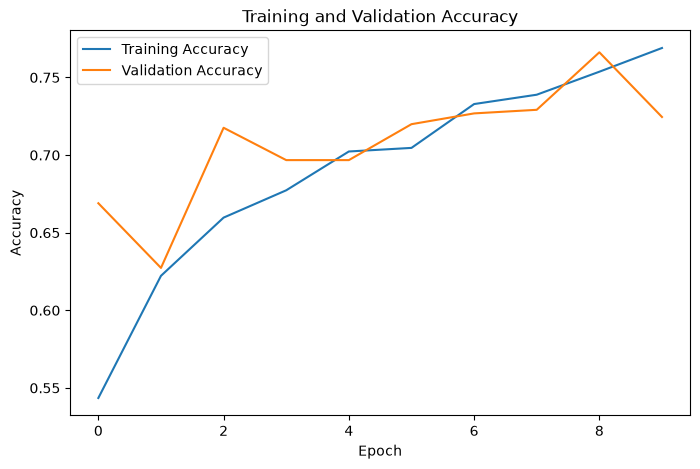

In [ ]:
# Plot Training and Validation Accuracy

acc = history["accuracy"]
val_acc = history["val_accuracy"]

plt.figure(figsize=(8, 5))
plt.plot(acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

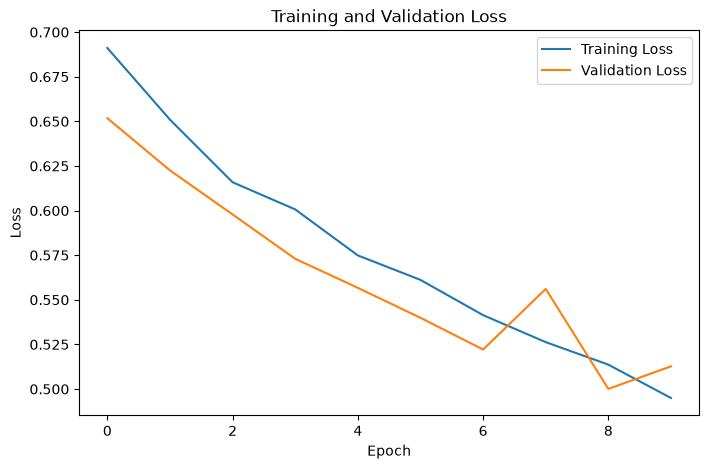

In [ ]:
# Plot Training and Validation Loss

loss = history["loss"]
val_loss = history["val_loss"]

plt.figure(figsize=(8, 5))
plt.plot(loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [ ]:
# Evaluation on the Test Set

test_loss, test_acc = evaluate_binary(model, test_generator, criterion, device)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

Test Loss: 0.5802296433183882
Test Accuracy: 0.6875


# Step 7 — Interpret the Learning Curves

**Short questions:**

1. Does the model improve over the epochs?
Yes, the loss decreases anf the accuracy increases as the epochs increase. 

2. Is there evidence of overfitting?

No clear evidence of overfitting after 10 epochs. Validation loss rises once at epoch 8, but it decreases again and reaches its minimum at epoch 10. The dips at epochs 5 and 8 are fluctuations due to the small validation set and noisy updates, not a trend. Training and validation curves stay close, and validation loss is even close to or below training loss for most epochs, partly because dropout is active during training but not during evaluation.
   
3. Around which epoch does validation performance stop improving?
   hasn’t clearly stopped. The best validation accuracy (0.769) and the lowest validation loss (0.500) are both at epoch 10, the last one. What you can say is that it’s starting to level off: validation loss only moves from 0.501 to 0.500 between epochs 9 and 10. To find the real stopping point, you’d need to train longer, for example 20–30 epochs with early stopping.
4. Are training and validation curves close or far apart?
   They are close: at epoch 10, training accuracy is 0.78 vs 0.77 on validation. This means the model generalizes about as well as it fits the training data: it hasn’t started memorizing the training images. Combined with accuracies that are still rising, it suggests the model is still underfitting slightly and could benefit from more epochs.

In [ ]:
# Generate Predictions on the Test Set

model.eval()
all_probs = []
all_true = []

with torch.no_grad():
    for xb, yb in test_generator:
        xb = xb.to(device)
        logits = model(xb)
        probs = torch.sigmoid(logits).cpu().numpy().reshape(-1)
        all_probs.append(probs)
        all_true.append(yb.numpy())

y_pred_probs = np.concatenate(all_probs)
y_true = np.concatenate(all_true)
y_pred = (y_pred_probs > 0.5).astype(int)

class_labels = [name for name, idx in sorted(test_dataset.class_to_idx.items(), key=lambda x: x[1])]

print("Number of test samples:", len(y_true))
print("First 10 predicted labels:", y_pred[:10])

Number of test samples: 288
First 10 predicted labels: [1 0 0 1 0 1 0 1 0 1]


# Step 8 — Make Predictions

The model outputs a raw logit; we apply `torch.sigmoid` manually to get a probability between 0 and 1.

- close to 0: one class
- close to 1: the other class

We convert probabilities into class labels using a threshold of `0.5`.

**Questions:**

1. What does a probability of `0.92` mean?

It means the model estimates P(dog | image) = 0.92 (dog = class 1), so P(cat | image) = 0.08. The image is classified as a dog with high confidence. This is the model’s estimate, given by the sigmoid of the network’s output logit; it is only a true frequency if the model is well calibrated, which is not guaranteed for neural networks.

2. Why do we use a threshold?

The model outputs a continuous probability, but classification requires a discrete decision (cat or dog), so we need a rule to convert it. With the threshold 0.5, we predict the most probable class. If the probabilities are well calibrated and both types of error cost the same, this choice minimizes the expected number of errors.

3. Could a different threshold change the results?

Yes. A treshold lower than 0.5 would mean that we favor classifying an image as a dog : we want to have as less false negative as possible : we favor recall. If we choose a treshold higher than 0.5, we favor detecting cats more than dogs : we want to have less false positive : we favor precision. 

Your model: cat recall is 0.66 and dog recall is 0.79, so the model leans towards “dog”. A threshold slightly above 0.5 would balance the two classes better.
Choose the threshold on the validation set, never the test set. Changing the threshold changes the predictions and the metrics (accuracy, precision, recall, confusion matrix). It doesn’t change the model, its probabilities or its loss.


# Short Improvement Ideas

Try **one** of the following changes:

- add `nn.Dropout(0.3)` after the dense layer *(already present in the baseline above — try increasing it)*
- replace `RMSprop` with `Adam`
- increase or decrease the number of filters
- use data augmentation in the training transform

Then compare the new curves with the baseline.

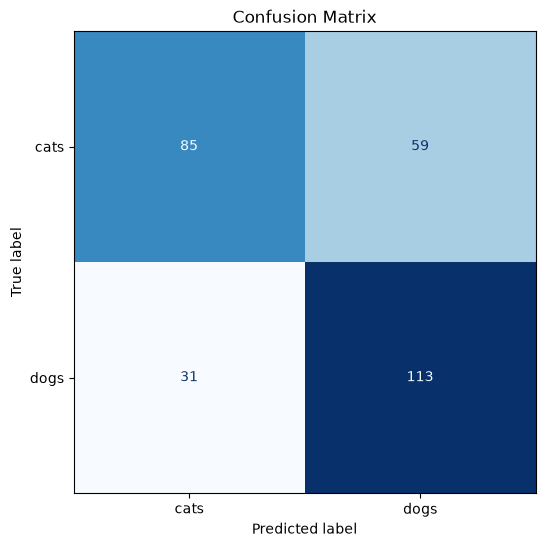

In [ ]:
#Confusion Matrix

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix")
plt.show()

In [ ]:
# Classification Report

print(classification_report(y_true, y_pred, target_names=class_labels))

              precision    recall  f1-score   support

        cats       0.73      0.59      0.65       144
        dogs       0.66      0.78      0.72       144

    accuracy                           0.69       288
   macro avg       0.69      0.69      0.68       288
weighted avg       0.69      0.69      0.68       288



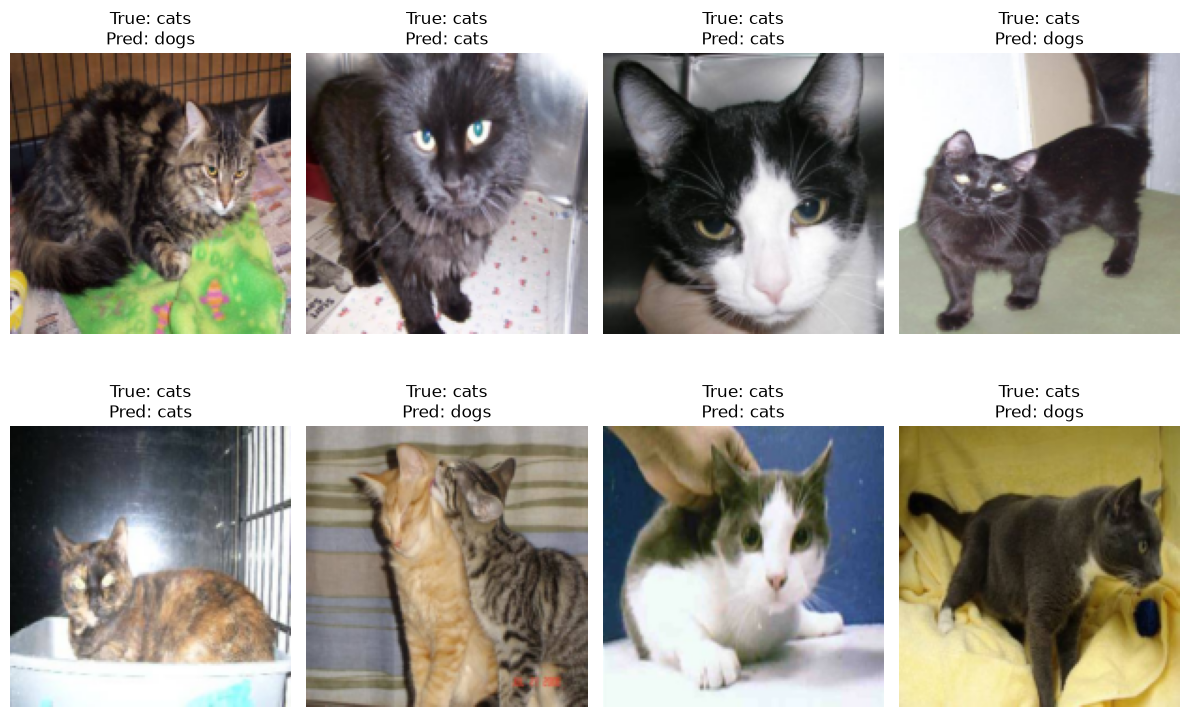

In [ ]:
# Show Some Test Predictions

sample_images, sample_labels = next(iter(test_generator))
with torch.no_grad():
    sample_probs = torch.sigmoid(model(sample_images.to(device))).cpu().numpy().reshape(-1)
sample_preds = (sample_probs > 0.5).astype(int)

plt.figure(figsize=(12, 8))
for i in range(min(8, len(sample_images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(sample_images[i].permute(1, 2, 0).numpy())
    true_label = class_labels[int(sample_labels[i])]
    pred_label = class_labels[int(sample_preds[i])]
    plt.title(f"True: {true_label}\nPred: {pred_label}")
    plt.axis("off")
plt.tight_layout()
plt.show()

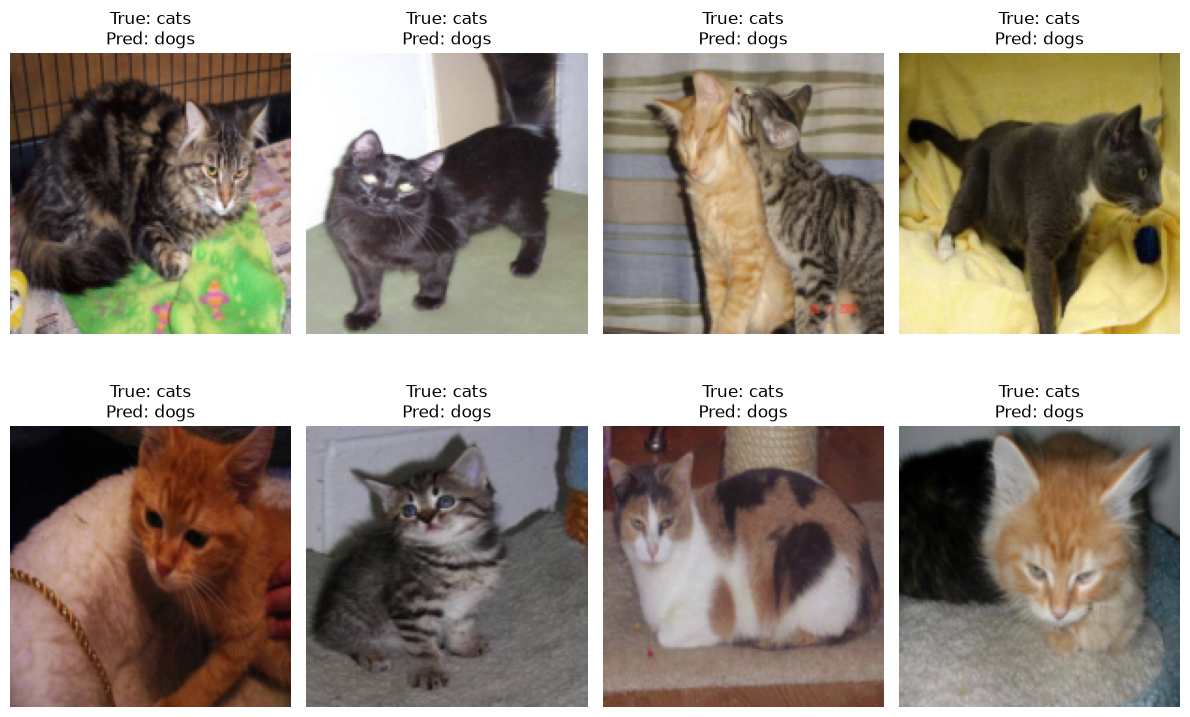

In [ ]:
# Show Misclassified Test Images

all_test_images = []
for xb, yb in test_generator:
    all_test_images.append(xb.numpy())
all_test_images = np.vstack(all_test_images)

misclassified_idx = np.where(y_pred != y_true)[0]

plt.figure(figsize=(12, 8))
for i, idx in enumerate(misclassified_idx[:8]):
    plt.subplot(2, 4, i + 1)
    plt.imshow(np.transpose(all_test_images[idx], (1, 2, 0)))
    true_label = class_labels[int(y_true[idx])]
    pred_label = class_labels[int(y_pred[idx])]
    plt.title(f"True: {true_label}\nPred: {pred_label}")
    plt.axis("off")
plt.tight_layout()
plt.show()

# Short Questions

1. Why is a CNN more suitable than an MLP for image classification?
2. What is the role of convolution layers?
3. What is the role of max pooling?
4. Based on the curves, does the model overfit?
5. Which class seems harder to classify?
6. What kinds of mistakes does the model make?
7. What would you try next to improve performance?

# Small optional improvement

If you want, you can replace the training transform with augmentation:

In [ ]:
train_transform_aug = transforms.Compose([
    transforms.Resize(image_size),
    transforms.RandomRotation(20),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.RandomResizedCrop(image_size, scale=(0.8, 1.0)),  # scale is a fraction of the image area, so at most 1.0
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

while keeping validation and test transforms with only:

In [ ]:
transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
])

Compose(
    Resize(size=(150, 150), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)

# Optional Improvement

Try one of the following:

- add more data augmentation
- change the number of filters
- add another convolution block
- change the dropout rate
- train for more epochs with early stopping

Then compare the new test results with the baseline model.

# Final Questions (Short Version)

Answer briefly:

1. Why is a CNN more appropriate than an MLP for images?
2. What is the difference between convolution and pooling?
3. Based on the curves, does your model overfit or generalize reasonably well?
4. What is one limitation of this baseline CNN?
5. What is one improvement you would test next?

# Mini Task

Modify the baseline model with **one improvement** and report:

1. What did you change?
2. Why did you choose this change?
3. Did validation accuracy improve?
4. Did overfitting increase or decrease?

In [ ]:
# Visualize augmented versions of the same training image

aug_check_dataset = datasets.ImageFolder(train_dir, transform=train_transform_aug)

plt.figure(figsize=(12, 6))
for i in range(8):
    img, label = aug_check_dataset[0]  # same image, a new random transformation each time
    plt.subplot(2, 4, i + 1)
    plt.imshow(img.permute(1, 2, 0).numpy())
    plt.title(f"Label: {label}")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
train_dataset_aug = datasets.ImageFolder(train_dir, transform=train_transform_aug)
train_generator_aug = DataLoader(train_dataset_aug, batch_size=batch_size, shuffle=True)

model_aug = BinaryCNN().to(device)
optimizer_aug = optim.RMSprop(model_aug.parameters(), lr=1e-4)
history_aug = train_binary_model(
    model_aug,
    train_generator_aug,
    validation_generator,
    criterion,
    optimizer_aug,
    device,
    epochs=30,
)


NameError: name 'datasets' is not defined

In [ ]:
# Compare the learning curves of the baseline and the augmented model

epochs_base = range(1, len(history["accuracy"]) + 1)
epochs_aug = range(1, len(history_aug["accuracy"]) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_base, history["accuracy"], "C0--", label="Baseline - train")
plt.plot(epochs_base, history["val_accuracy"], "C0-", label="Baseline - validation")
plt.plot(epochs_aug, history_aug["accuracy"], "C1--", label="Augmentation - train")
plt.plot(epochs_aug, history_aug["val_accuracy"], "C1-", label="Augmentation - validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_base, history["loss"], "C0--", label="Baseline - train")
plt.plot(epochs_base, history["val_loss"], "C0-", label="Baseline - validation")
plt.plot(epochs_aug, history_aug["loss"], "C1--", label="Augmentation - train")
plt.plot(epochs_aug, history_aug["val_loss"], "C1-", label="Augmentation - validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Compare both models on the test set

def predict_binary(model, data_loader, device):
    model.eval()
    all_probs = []
    with torch.no_grad():
        for xb, _ in data_loader:
            all_probs.append(torch.sigmoid(model(xb.to(device))).cpu().numpy().reshape(-1))
    return (np.concatenate(all_probs) > 0.5).astype(int)

for name, m in [("Baseline", model), ("Augmentation", model_aug)]:
    m_test_loss, m_test_acc = evaluate_binary(m, test_generator, criterion, device)
    print(f"===== {name} - test loss: {m_test_loss:.4f} - test accuracy: {m_test_acc:.4f}")
    print(classification_report(y_true, predict_binary(m, test_generator, device), target_names=class_labels))